# §57 — EDA of the cut DoTA train corpus (`DoTA_train_window`)

Rule: `core/docs/final/KIM_RUN.md` **§57**. Upload branch `v_final_las_vad` to `Thesis-Final/kat-vad` first. **CPU only** (no GPU needed), about 2-3 min. Dataset properties only: no model, nothing gates, no arm follows.

The windows are rebuilt from DoTA's annotation zip and the frozen train map with the planner that wrote the corpus, then **gated** window by window against `Thesis-Final/data/DoTA_train_window` (§55).

| step | what |
|---|---|
| 1-2 | mount, paths, code check |
| 3 | annotation zip (sha256 checked against the frozen map) |
| 4 | tests of the touched code — **raises if red** |
| 5 | EDA + gate + figures -> `Thesis-Final/outputs/dota_eda/REPORTS/`; **paste `dota_eda_report.md` to Claude** |

In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import hashlib
import os
import shutil
import subprocess
import sys
import urllib.request
from pathlib import Path

DRIVE    = '/content/drive/MyDrive/Thesis'        # read-only
DRIVE_F  = '/content/drive/MyDrive/Thesis-Final'  # code, the §55 corpus; every output of this notebook
os.environ['PROJECT_ROOT']       = DRIVE_F
os.environ['KATVAD_DATA_ROOT']   = f'{DRIVE}/data'
os.environ['KATVAD_CACHE_ROOT']  = f'{DRIVE_F}/cache'
os.environ['KATVAD_CKPT_ROOT']   = f'{DRIVE}/ckpts'
os.environ['KATVAD_OUTPUT_ROOT'] = f'{DRIVE_F}/outputs'

REPO = Path(f'{DRIVE_F}/kat-vad')
assert (REPO / 'core' / 'constants.py').is_file(), f'no code at {REPO} -- upload branch v_final_las_vad there'
assert '## 57. ' in (REPO / 'core/docs/final/KIM_RUN.md').read_text(), 'KIM_RUN.md has no §57 -- re-upload kat-vad/'
assert (REPO / 'core/tools/dota_eda.py').is_file(), 'no core/tools/dota_eda.py -- re-upload kat-vad/'
assert 'def plan(' in (REPO / 'core/tools/dota_train_build.py').read_text(), 'dota_train_build has no plan() -- re-upload kat-vad/'
os.environ['PYTHONPATH'] = str(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
for name in [m for m in sys.modules if m == 'core' or m.startswith('core.')]:
    del sys.modules[name]              # constants reads KATVAD_* at import time
from core import constants  # noqa: E402

assert constants.REPO_ROOT == REPO, f'imported core from {constants.REPO_ROOT}, expected {REPO}'
DATA    = Path(DRIVE_F) / 'data' / constants.DOTA_TRAIN_CORPUS_DIRNAME
REPORTS = constants.OUTPUT_ROOT / constants.DOTA_EDA_OUTPUT_DIRNAME / 'REPORTS'
LOCAL   = Path('/content/dota_eda')
LOCAL.mkdir(parents=True, exist_ok=True)
for f in (constants.LABELS_TRAIN_FILENAME, constants.META_FILENAME):
    assert (DATA / f).is_file(), f'no {DATA / f}: run k5dfidota.ipynb (§55) first'
print(f'corpus {DATA} | reports -> {REPORTS}')


def run(cmd):
    """Stream a child's output; raise with its tail on failure."""
    tail = []
    env = dict(os.environ, MPLBACKEND='Agg')
    with subprocess.Popen([str(c) for c in cmd], cwd=str(REPO), env=env, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True, bufsize=1) as proc:
        for line in proc.stdout:
            tail = (tail + [line])[-40:]
            print(line, end='')
    if proc.returncode:
        print('\n' + '=' * 30 + f'\nFAILED (exit {proc.returncode}) -- paste these lines to Claude:\n' + ''.join(tail))
        raise RuntimeError(f'exit {proc.returncode}')

corpus /content/drive/MyDrive/Thesis-Final/data/DoTA_train_window | reports -> /content/drive/MyDrive/Thesis-Final/outputs/dota_eda/REPORTS


In [3]:
import json  # noqa: E402

ANN = LOCAL / 'DoTA_annotations.zip'              # DoTA's official annotation zip (10 MB)
if not ANN.exists():
    urllib.request.urlretrieve('https://github.com/MoonBlvd/Detection-of-Traffic-Anomaly/raw/master/dataset/DoTA_annotations.zip', ANN)
frozen = json.loads((constants.DOTA_TRAIN_SPLITS_DIR / constants.DOTA_TRAIN_MAP_FILENAME).read_text())
assert hashlib.sha256(ANN.read_bytes()).hexdigest() == frozen['sources']['annotations_sha256'], 'annotation zip is not the one the map was built on'
print('annotations OK')

annotations OK


In [6]:
%%bash
pip install -q av

## 4. Tests (CPU) — **raises if anything fails: stop and paste the output**

In [7]:
run([sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'core/tests/test_dota_eda.py',
     'core/tests/test_dota_train_corpus.py', 'core/tests/test_nexar_eda.py'])

.............................................                            [100%]
45 passed in 51.08s


## 5. EDA + gate + figures -> **paste `REPORTS/dota_eda_report.md` to Claude**

INFO core.data.dada: Windowing: 12937 windows of 12 frames (hop 6, <=10000 per clip) over 3019/3020 clips; dropped 1 too short, 0 weak-abnormal (drop)
INFO core.data.dada: Abnormal source retention: 3019/3020 (100.0%)
WARNING core.data.dada: 1 clips are shorter than 12 sampled frames and contribute no window: ['r6_ZhT7rmhM_004291'] -- they are NOT padded (lesson C27)
INFO __main__: DoTA EDA -> /content/dota_eda/report


# DoTA train corpus EDA (`DoTA_train_window`, KIM_RUN.md §57)

Stride 3 (0.3 s / row) · windows 12 rows, hop 6 · dataset properties only, no model, nothing gates.

Gate: rebuilt windows == corpus on disk, 12937 windows checked.

## 1. Clips

|  | value |
|---|---|
| clips | 3020 |
| clips with no abnormal row | 2 |
| YouTube ids | 186 |
| span reaches the clip end (<= 1 row) | 0.105 |
| span starts at row 0 | 0.000 |
| normal rows before span < one window (12) | 0.420 |
| ego-involved | 0.608 |
| night | 0.121 |

- seconds: mean 10.187; p0 3.300 / p25 8.300 / **p50 9.900** / p75 11.700 / p100 30.000
- rows: mean 34.285; p0 11.000 / p25 28.000 / **p50 33.000** / p75 39.000 / p100 100.000
- span_rows: mean 11.081; p0 1.000 / p25 7.000 / **p50 10.000** / p75 14.000 / p100 64.000
- span_share: mean 0.325; p0 0.022 / p25 0.212 / **p50 0.300** / p75 0.410 / p100 0.938
- start_rel: mean 0.391; p0 0.000 / p25 0.298 / **p50 0.379** / p75 0.471 / p100 0.950
- end_rel: mean 0.716; p0 0.176 / p25 0.606 / **p50 0.714** / p75 0.828 / p100 1.000
- center_rel: mean 0.553; p0 0.118 / p25 0.468 / **p50 0.548** / p75 0.635 / p100 0.975
- pre_rows: mean 13.180; p0 0.000 / p25 9.250 / **p50 12.000** / p75 16.000 / p100 77.000
- post_rows: mean 10.028; p0 0.000 / p25 5.250 / **p50 9.000** / p75 13.000 / p100 77.000

Accident class (share of clips):

| class | share |
|---|---|
| turning | 0.380 |
| lateral | 0.152 |
| moving_ahead_or_waiting | 0.144 |
| oncoming | 0.105 |
| leave_to_left | 0.077 |
| leave_to_right | 0.072 |
| start_stop_or_stationary | 0.019 |
| pedestrian | 0.018 |
| obstacle | 0.017 |
| unknown | 0.016 |

## 2. Time profile of the abnormal rows

Row abnormal share: 0.323.

| relative bin | abnormal share |
|---|---|
| 0.0-0.1 | 0.006 |
| 0.1-0.2 | 0.051 |
| 0.2-0.3 | 0.185 |
| 0.3-0.4 | 0.430 |
| 0.4-0.5 | 0.648 |
| 0.5-0.6 | 0.703 |
| 0.6-0.7 | 0.579 |
| 0.7-0.8 | 0.362 |
| 0.8-0.9 | 0.187 |
| 0.9-1.0 | 0.086 |

| row (1 = last / first) | from the clip end | from the clip start |
|---|---|---|
| 1 | 0.082 | 0.000 |
| 2 | 0.105 | 0.004 |
| 3 | 0.125 | 0.009 |
| 4 | 0.152 | 0.018 |
| 5 | 0.182 | 0.031 |
| 6 | 0.229 | 0.055 |
| 7 | 0.277 | 0.084 |
| 8 | 0.335 | 0.125 |
| 9 | 0.394 | 0.168 |
| 10 | 0.459 | 0.246 |

No-pixel row rulers (AUC; 0.5 = nothing):

| micro late | micro hump | macro late | macro hump | two-class clips |
|---|---|---|---|---|
| 0.585 | 0.807 | 0.594 | 0.832 | 3018 |

## 3. Windows

12937 windows = 9386 positive + 3551 normal from 3019 clips; clips without a normal window 944.

- normal / clip: mean 1.176; p0 0.000 / p25 0.000 / **p50 1.000** / p75 2.000 / p100 12.000
- positive / clip: mean 3.109; p0 0.000 / p25 2.000 / **p50 3.000** / p75 4.000 / p100 10.000
- abnormal rows / positive window: mean 6.417; p0 1.000 / p25 4.000 / **p50 6.000** / p75 9.000 / p100 12.000; <= 1: 0.072, <= 2: 0.152, <= 3: 0.243, <= 6: 0.532; whole window: 0.129
- row profile inside a positive window: 0.442 0.470 0.489 0.509 0.529 0.547 0.560 0.568 0.571 0.575 0.579 0.577
- normal windows: 2500 before the span, 1044 after; gap rows mean 5.366; p0 0.000 / p25 1.000 / **p50 3.000** / p75 7.000 / p100 65.000; within 2 rows 0.420

V2-S padding: rows < 5 of a clip see a clamped (repeated) first frame.

|  | normal windows | positive windows |
|---|---|---|
| share holding padded rows | 0.493 | 0.135 |
| share touching the clip end | 0.042 | 0.036 |

No-pixel window rulers (AUC of the window label):

| centre raw | centre hump | raw within clip | hump within clip | padded rows | touches end |
|---|---|---|---|---|---|
| 0.677 | 0.790 | 0.760 | 0.859 | 0.321 | 0.497 |

Positive rate by stratum (windows):

| ego | normal | positive | clips | positive rate |
|---|---|---|---|---|
| ego | 2074 | 5491 | 1834 | 0.726 |
| other | 1477 | 3895 | 1185 | 0.725 |

| night | normal | positive | clips | positive rate |
|---|---|---|---|---|
| day | 3066 | 8257 | 2655 | 0.729 |
| night | 485 | 1129 | 364 | 0.700 |

| accident | normal | positive | clips | positive rate |
|---|---|---|---|---|
| turning | 1224 | 3307 | 1149 | 0.730 |
| lateral | 525 | 1512 | 459 | 0.742 |
| moving_ahead_or_waiting | 525 | 1333 | 434 | 0.717 |
| oncoming | 428 | 876 | 318 | 0.672 |
| leave_to_left | 288 | 907 | 232 | 0.759 |
| leave_to_right | 264 | 805 | 217 | 0.753 |
| start_stop_or_stationary | 84 | 168 | 56 | 0.667 |
| pedestrian | 90 | 158 | 54 | 0.637 |
| obstacle | 65 | 161 | 52 | 0.712 |
| unknown | 58 | 159 | 48 | 0.733 |

MIL k on a 12-row window: `L_MIL` k = 2 (pct 5), multi-class k = 1 (pct 16), bottom-k arms (§56) k = 2.



span_position.png


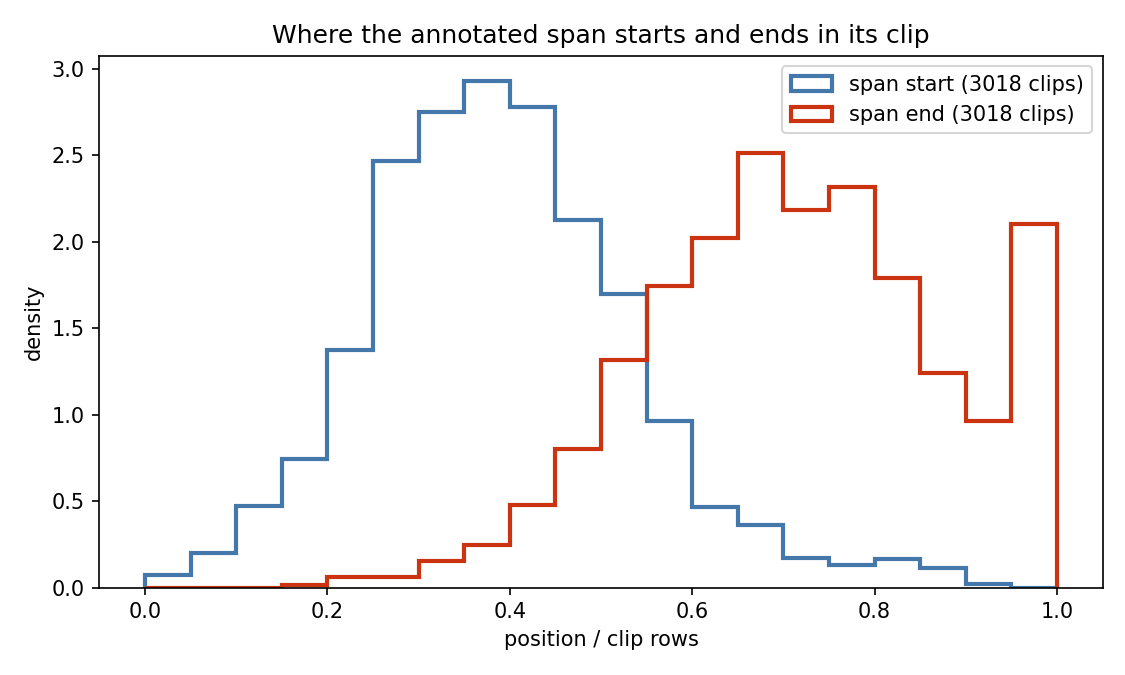

time_profile.png


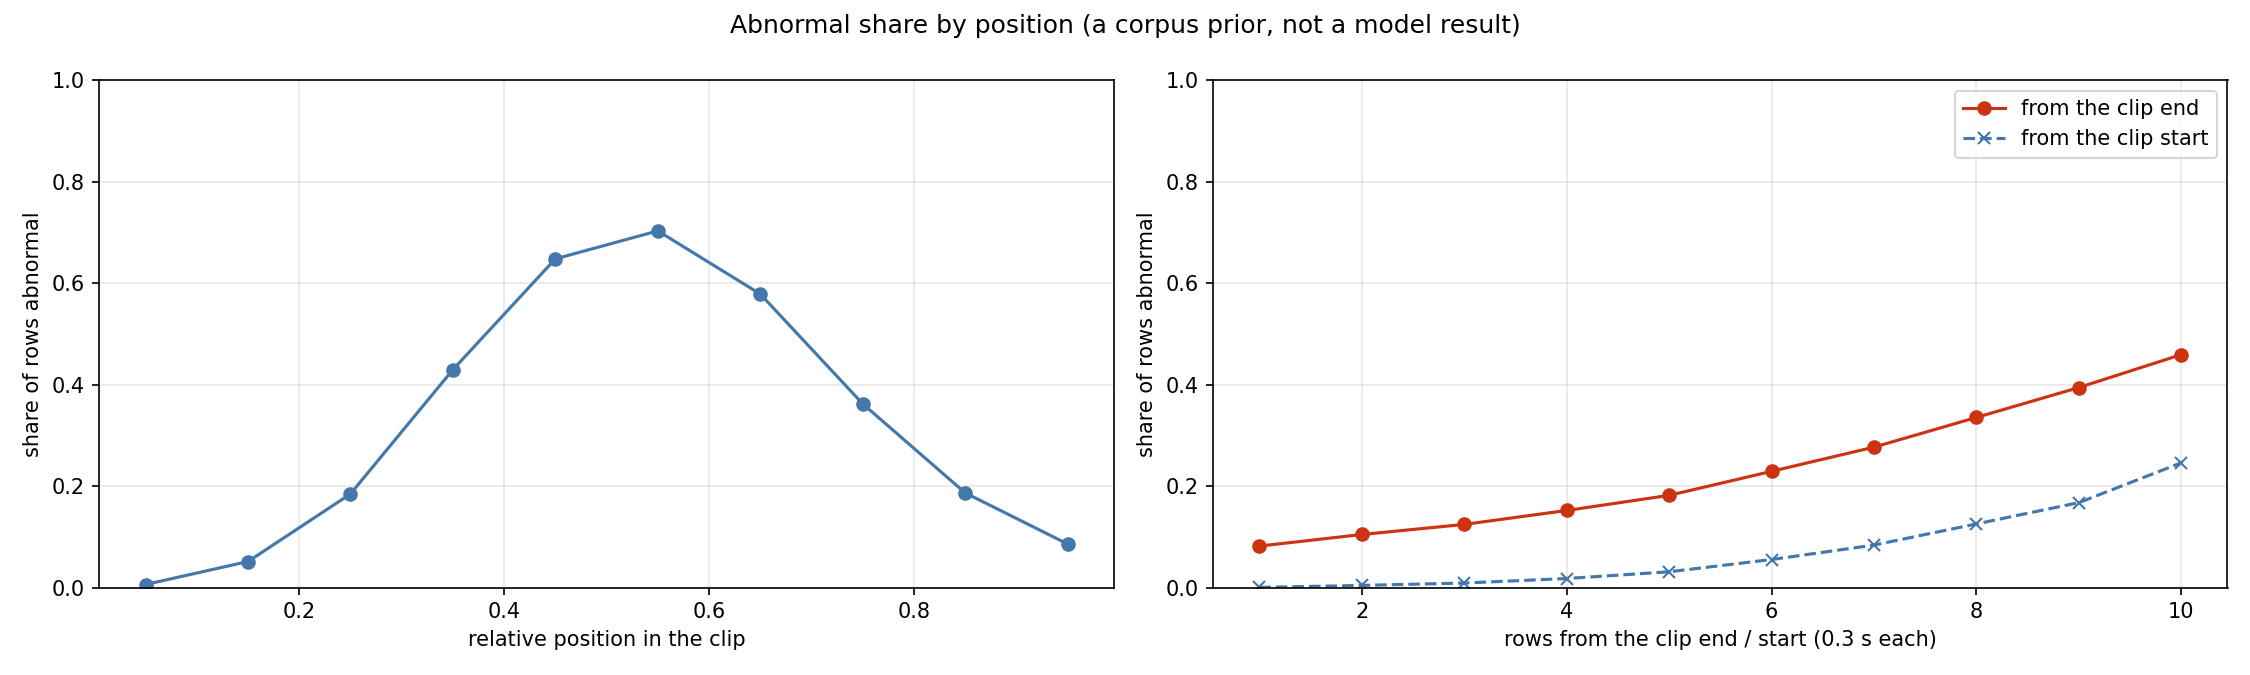

abnormal_rows_per_positive_window.png


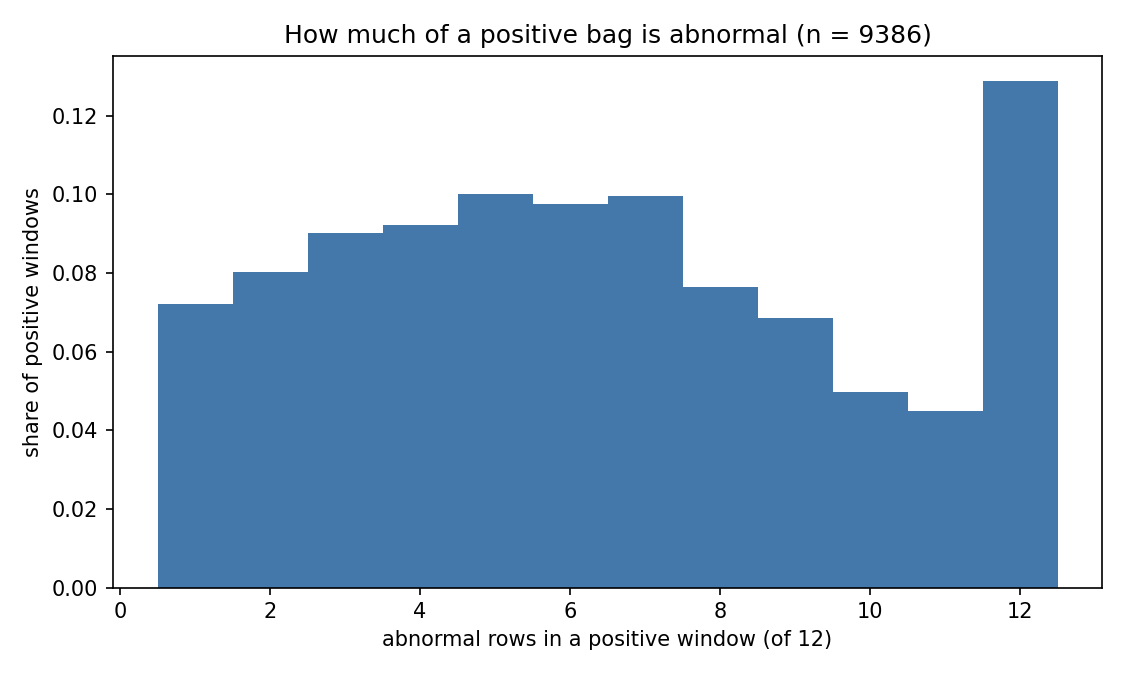

normal_gap_to_span.png


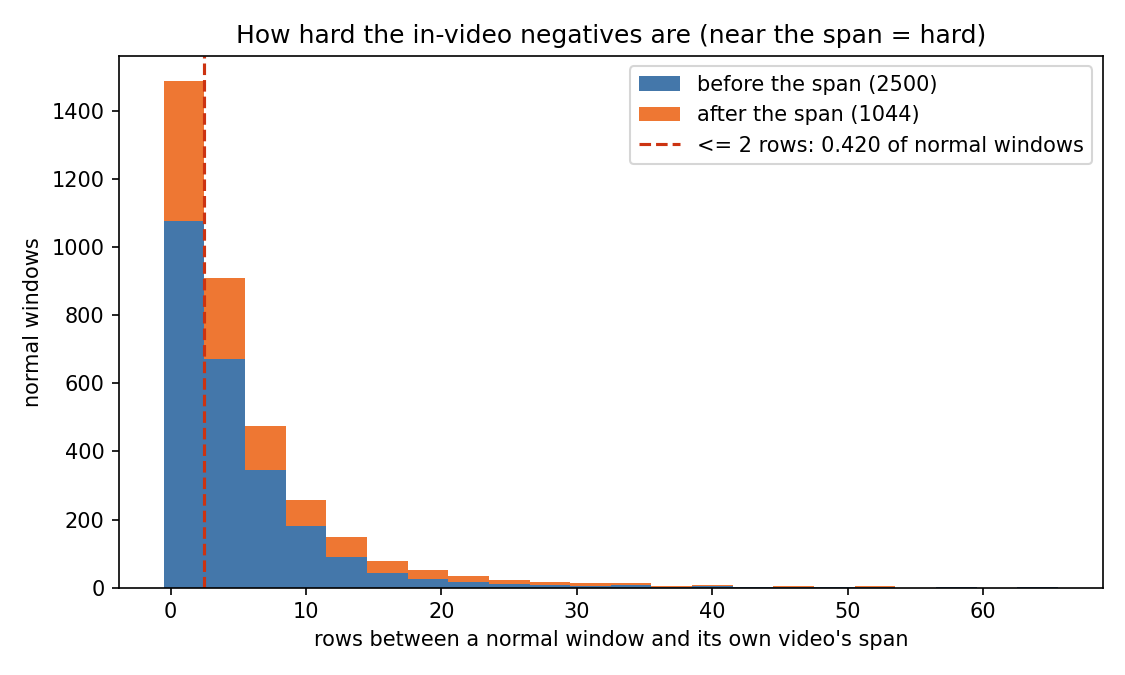

window_center_by_class.png


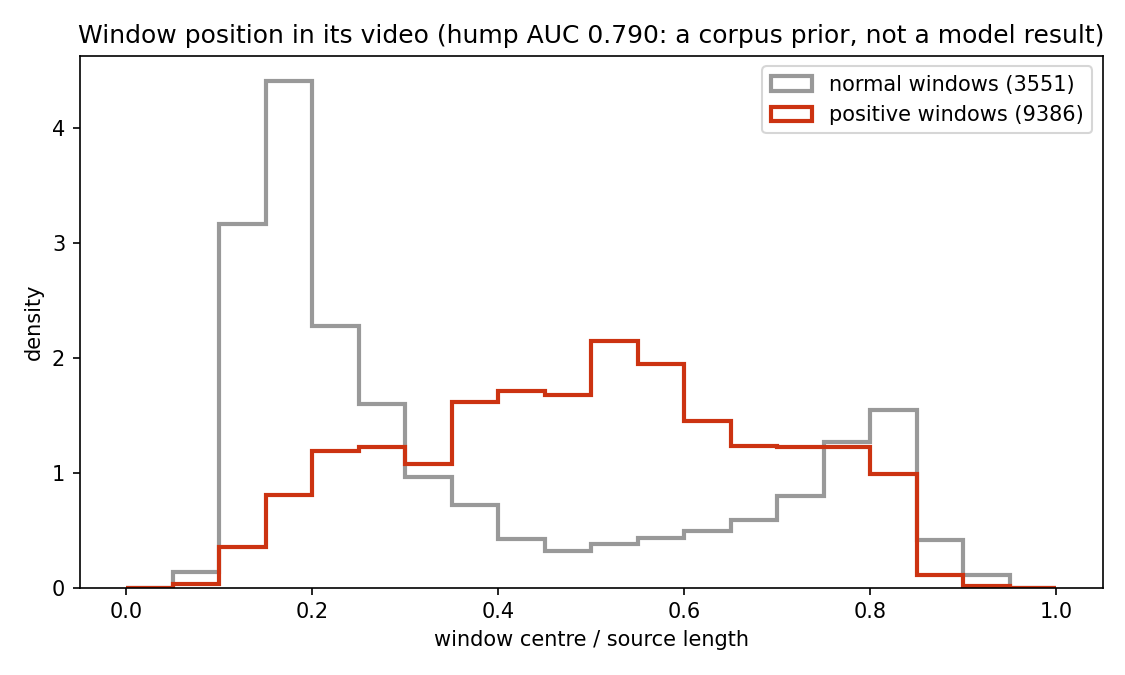

strata.png


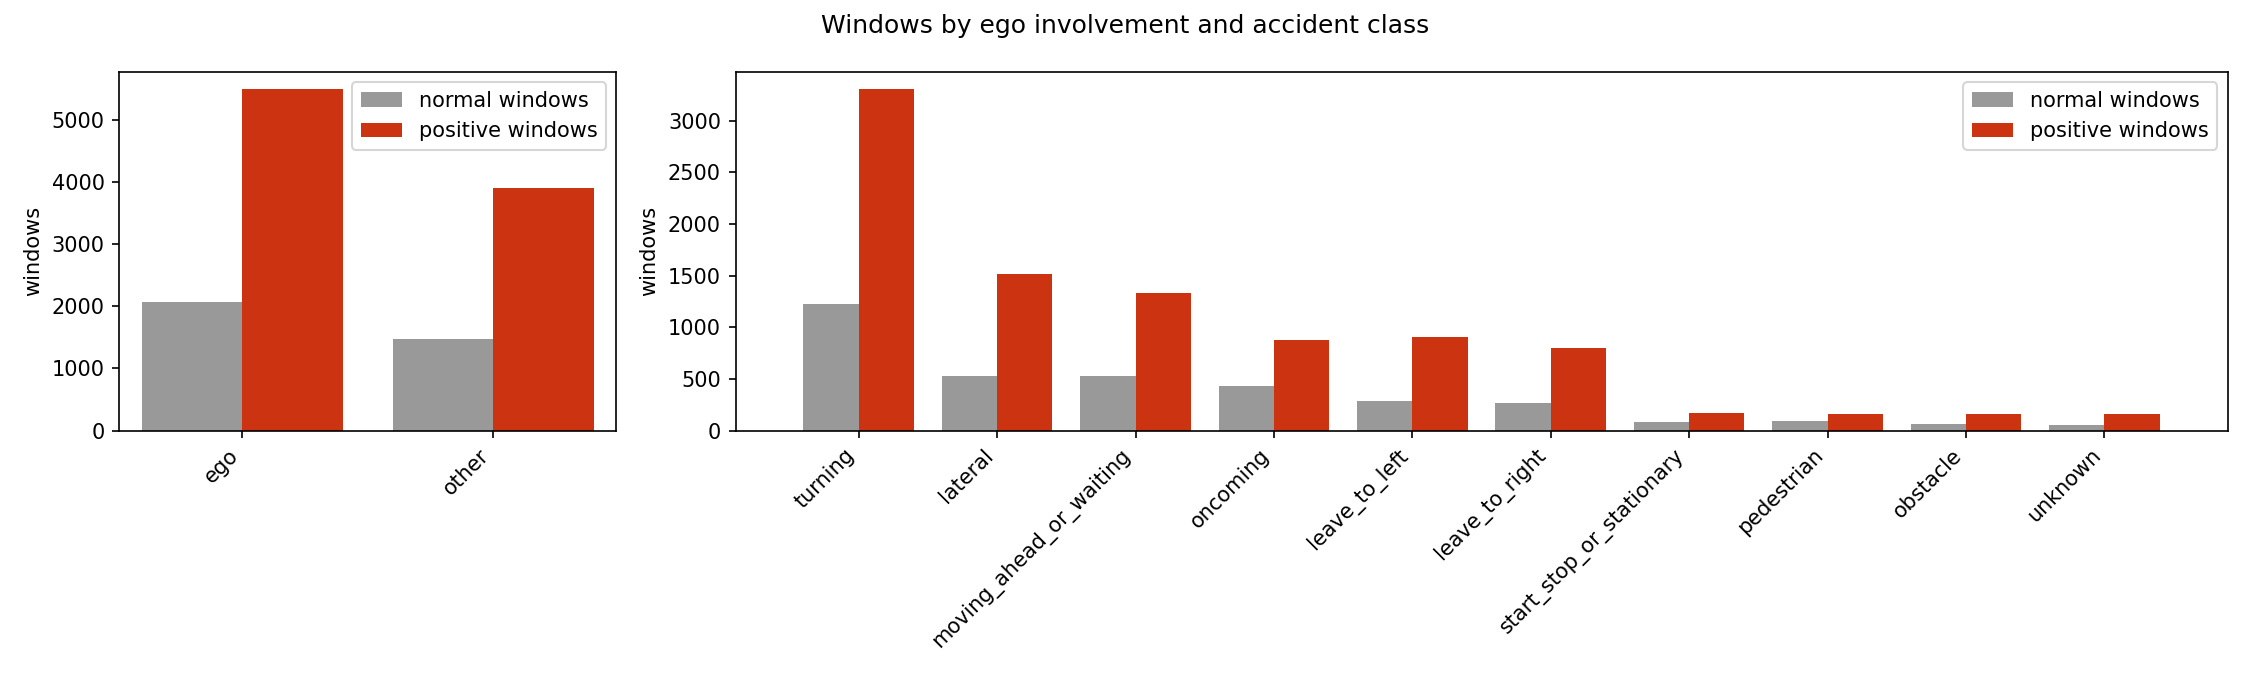

Drive flushed -- paste REPORTS/dota_eda_report.md to Claude


In [8]:
from IPython.display import Image as Show, Markdown, display  # noqa: E402

out = LOCAL / 'report'
shutil.rmtree(out, ignore_errors=True)
run([sys.executable, '-m', 'core.tools.dota_eda', '--annotations', ANN, '--data-dir', DATA, '--output-dir', out, '--plots'])
REPORTS.mkdir(parents=True, exist_ok=True)
shutil.copytree(out, REPORTS, dirs_exist_ok=True)
report = json.loads((REPORTS / f'{constants.DOTA_EDA_REPORT_STEM}.json').read_text())
assert report['gate'] and report['gate']['equal'] and report['gate']['windows_checked'] == 12937, report['gate']
display(Markdown((REPORTS / f'{constants.DOTA_EDA_REPORT_STEM}.md').read_text()))
for name in report['figures']:
    print(name)
    display(Show(filename=str(REPORTS / constants.NEXAR_EDA_FIGURES_DIRNAME / name)))
drive.flush_and_unmount()          # C10: every pending Drive write lands before the VM goes
print('Drive flushed -- paste REPORTS/dota_eda_report.md to Claude')